# 01 · Understanding the Data

**Business question:** which credit card customers are likely to miss next month's payment, so the bank can act early (review the credit limit, offer a repayment plan) instead of writing off the debt later?

**Data:** 30,000 credit card customers of a Taiwanese bank, April–September 2005 ([UCI](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), CC BY 4.0). For each customer: credit limit, six months of repayment status, statement balances and payments, a few demographics, and whether they defaulted in October 2005.

This notebook checks the data's quirks and finds out which signals carry information, *before* any modelling.

In [1]:
import numpy as np
import pandas as pd

from credit_risk import config, data, evaluation, explain, fairness, plots, train

plots.set_style()
pd.set_option("display.precision", 3)
FIG, TABLES = config.FIGURES_DIR, config.TABLES_DIR

raw = data.load_raw()
df = data.clean(raw)
print(f'{len(df):,} customers, default rate {df[config.TARGET].mean():.1%}')

30,000 customers, default rate 22.1%


## 1. Quirks in the source data

**Column naming.** The repayment columns are named `PAY_0, PAY_2, ..., PAY_6`: there is no `PAY_1`. `data.clean` renames `PAY_0` to `PAY_1` so that month 1 means September in every column group (`PAY_1`, `BILL_AMT1`, `PAY_AMT1`).

**Undocumented repayment codes.** The documentation says −1 = paid on time and 1–9 = months late. But the data also contains **−2** and **0**, which are not documented. Their meaning can be inferred from the balances:

In [2]:
codes = df.groupby("PAY_1").agg(
    customers=("ID", "size"),
    default_rate=(config.TARGET, "mean"),
    zero_bill_share=("BILL_AMT1", lambda s: (s <= 0).mean()),
    median_bill=("BILL_AMT1", "median"),
)
codes

,customers,default_rate,zero_bill_share,median_bill
PAY_1,,,,
-2,2759,0.132,0.327,1179.0
-1,5686,0.168,0.001,2739.5
0,14737,0.128,0.000,49605.0
1,3688,0.339,0.458,4606.5
2,2667,0.691,0.000,41632.0
3,322,0.758,0.000,18354.0
4,76,0.684,0.000,31633.0
5,26,0.500,0.000,39752.5
6,11,0.545,0.000,71310.0


- **−2**: a third have no balance at all, so this most likely means *no balance / card not used*.
- **−1**: small balances, low default rate: *paid in full*.
- **0**: by far the largest balances (median NT$49,600) with a low default rate: *revolving credit*, paying at least the minimum. This is the most common status.
- **1** looks inconsistent: "1 month late", but 46% have a zero bill. It is also common in September (3,688 customers) yet almost absent in later months:

In [3]:
(df[config.STATUS] == 1).sum().rename("customers coded '1 month late'").to_frame().T

,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
customers coded '1 month late',3688,28,4,2,0,0


That pattern suggests the code was recorded differently in September than in earlier months. The model treats status codes as numbers and also gets explicit counts of each status, so it can learn what each code means in practice without relying on the documentation.

**Other quirks:** education codes 0, 4, 5, 6 and marital status 0, 3 are undocumented or "other", so they are grouped as *Other / unknown*. 1,930 customers have a negative bill in at least one month, which is valid (they overpaid and the card holds a credit).

## 2. What predicts default?

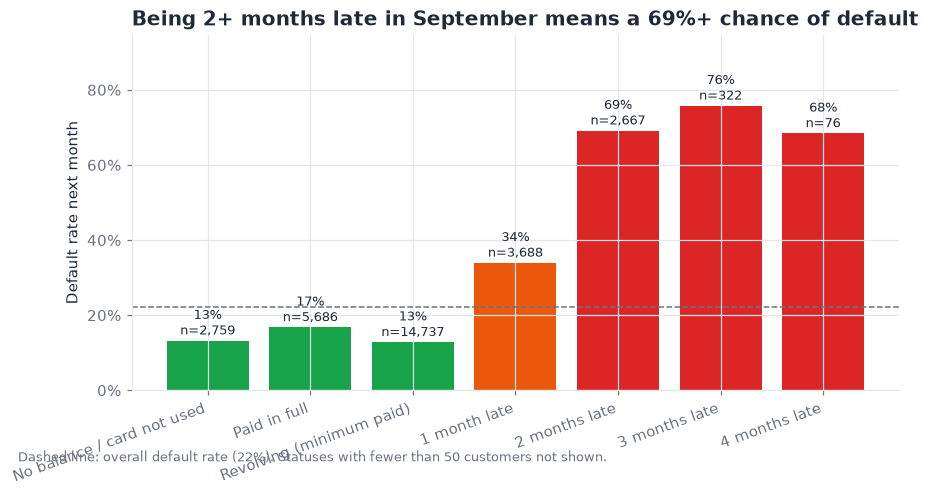

In [4]:
plots.default_by_status(df, FIG / "01_default_by_status.png");

The latest repayment status is a very strong signal: being 2 or more months late in September means roughly a 70% chance of default in October, against 13–17% for customers who are up to date.

In [5]:
from credit_risk.features import add_features

features = pd.concat([df, add_features(df).drop(columns=config.BEHAVIOUR)], axis=1)
features["utilization band"] = pd.cut(features["utilization_avg"], [-0.01, 0.1, 0.3, 0.6, 0.9, 10],
                                      labels=["<10%", "10-30%", "30-60%", "60-90%", "90%+"])
features["limit band"] = pd.qcut(features["LIMIT_BAL"], 5, duplicates="drop")
pd.concat({
    "by average utilization": features.groupby("utilization band", observed=True)[config.TARGET].agg(["size", "mean"]),
    "by credit limit (quintiles)": features.groupby("limit band", observed=True)[config.TARGET].agg(["size", "mean"]),
}).rename(columns={"size": "customers", "mean": "default rate"})

customers  default rate
by average utilization      <10%                       11034         0.188
                            10-30%                      4224         0.156
                            30-60%                      5472         0.219
                            60-90%                      6468         0.277
                            90%+                        2802         0.326
by credit limit (quintiles) (9999.999, 50000.0]         7676         0.318
                            (50000.0, 100000.0]         4822         0.258
                            (100000.0, 180000.0]        6123         0.199
                            (180000.0, 270000.0]        5421         0.169
                            (270000.0, 1000000.0]       5958         0.138

- **Customers using most of their limit default more**: above 90% average utilization, 33% default, about double the rate of customers using 10–30% (16%). The very lowest band (under 10%) is slightly riskier than 10–30%, because it includes inactive cards and customers who have stopped using credit.
- **Lower credit limits go with higher default rates** (32% in the lowest fifth of limits vs 14% in the highest). The limit partly reflects the bank's own earlier risk assessment, so it is a legitimate and informative input.

These two relationships motivated the engineered features in `features.py`: utilization, payment-to-bill ratios, and counts of months in each repayment status.

## 3. Should demographics be model inputs?

The data includes sex, age, education and marital status. Using them to make credit decisions is legally restricted in many countries, and ethically questionable everywhere. Before deciding, it's worth measuring what excluding them would cost:

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score

train_df, _ = data.split(df)   # only training data, the test set stays untouched
y = train_df[config.TARGET]
model_hgb = HistGradientBoostingClassifier(random_state=config.SEED)
auc = {
    "Behaviour only": cross_val_score(model_hgb, train_df[config.BEHAVIOUR], y, cv=evaluation.cv(), scoring="roc_auc"),
    "Behaviour + demographics": cross_val_score(model_hgb, train_df[config.BEHAVIOUR + config.DEMOGRAPHICS], y, cv=evaluation.cv(), scoring="roc_auc"),
}
pd.DataFrame({k: {"mean ROC-AUC": v.mean(), "std": v.std()} for k, v in auc.items()}).T

,mean ROC-AUC,std
Behaviour only,0.780,0.005
Behaviour + demographics,0.782,0.005


Adding demographics improves ROC-AUC by about **0.002**, well within the fold-to-fold noise. Payment behaviour already carries almost all the information.

**Decision:** the model uses **behaviour only**. Demographics are kept in the data solely to **audit** the model's decisions for fairness (notebook 03). Leaving a variable out doesn't guarantee fairness, because behaviour can correlate with demographics, so the audit is still needed.